## Data: Sleeper's public API, cached on disk

Every request goes through `get()`, which keeps a gzipped copy under `notebooks/.cache/sleeper/` (git-ignored). All seasons used
here are finished, so a cached response never goes stale. The first run downloads a few thousand small files (a few minutes
under Sleeper's rate limit); later runs read the cache.

**Which leagues.** The owner's own finished league is *goon squad* (2025, 8 teams). It has 8 playoff spots for 8 teams, so every
team makes the playoffs and it says nothing about playoff odds; it still counts for title and flush odds. No other finished
league is reachable from the owner's account: the members of both of the owner's leagues play in no other Sleeper league.
To get enough seasons, the notebook widens the net from two **public example leagues** that the open-source `ffscrapr` R package
uses in its documentation (league ids `522458773317046272` and `521379020332068864`). It takes their members' 2023-2025 leagues and
keeps the ordinary ones:

* finished (`status == complete`), head-to-head (no best ball, no extra game against the league median),
* 8 to 14 teams, fewer playoff spots than teams, playoffs starting in week 14-16,
* offense-only lineups (no IDP slots, which the projections here do not cover).

Only aggregate numbers are reported. Apart from the owner's own league, league names, team names and usernames are never printed; other leagues are shown as a short hash.

In [1]:
import gzip, hashlib, json, time, urllib.request, urllib.error
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np, pandas as pd

CACHE = Path('.cache') / 'sleeper'
CACHE.mkdir(parents=True, exist_ok=True)
BASE = 'https://api.sleeper.app'

def get(path):
    """GET a Sleeper path (e.g. '/v1/league/123'), cached forever on disk. Returns None on a 404."""
    f = CACHE / (hashlib.sha1(path.encode()).hexdigest()[:20] + '.json.gz')
    if f.exists():
        with gzip.open(f, 'rt') as fh: return json.load(fh)
    for attempt in range(5):
        try:
            with urllib.request.urlopen(BASE + path, timeout=30) as r:
                data = json.load(r)
            break
        except urllib.error.HTTPError as e:
            if e.code == 404: data = None; break
            time.sleep(1 + 2 * attempt)
        except Exception:
            time.sleep(1 + 2 * attempt)
    else:
        raise RuntimeError('failed: ' + path)
    with gzip.open(f, 'wt') as fh: json.dump(data, fh)
    return data

def get_many(paths, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(get, paths))

anon = lambda lid: hashlib.sha1(str(lid).encode()).hexdigest()[:6]

OWNER_USER = '1270089224720232448'
OWNER_LEAGUE_2025 = '1270085638657413120'           # goon squad
PUBLIC_SEEDS = ['522458773317046272', '521379020332068864']
SEASONS = ['2023', '2024', '2025']
OFFENSE_SLOTS = {'QB', 'RB', 'WR', 'TE', 'K', 'DEF', 'FLEX', 'SUPER_FLEX', 'REC_FLEX', 'WRRB_FLEX'}
NON_LINEUP = {'BN', 'IR', 'TAXI'}

def ordinary(l):
    s = l.get('settings') or {}
    slots = [p for p in l.get('roster_positions') or [] if p not in NON_LINEUP]
    n, P = l.get('total_rosters') or 0, s.get('playoff_teams') or 6
    return (l.get('status') == 'complete' and not s.get('best_ball') and not s.get('league_average_match')
            and 8 <= n <= 14 and P < n and 14 <= (s.get('playoff_week_start') or 15) <= 16
            and all(x in OFFENSE_SLOTS for x in slots) and s.get('type', 0) in (0, 1, 2))

owner_leagues = get(f'/v1/user/{OWNER_USER}/leagues/nfl/2025') or []
members = sorted({u['user_id'] for lid in PUBLIC_SEEDS for u in (get(f'/v1/league/{lid}/users') or [])})
found = {}
for lists in get_many([f'/v1/user/{u}/leagues/nfl/{y}' for u in members for y in SEASONS]):
    for l in lists or []: found[l['league_id']] = l
ext = sorted((l for l in found.values() if ordinary(l)), key=lambda l: (l['season'], l['league_id']))
print('owner 2025 leagues:', [(l['name'], l['total_rosters'], l['settings'].get('playoff_teams')) for l in owner_leagues])
print(f'public-seed members: {len(members)}, their 2023-25 leagues: {len(found)}, ordinary: {len(ext)}')
print(pd.Series([l['season'] for l in ext]).value_counts().sort_index().to_dict())

owner 2025 leagues: [('goon squad', 8, 8)]
public-seed members: 24, their 2023-25 leagues: 177, ordinary: 106
{'2023': 42, '2024': 35, '2025': 29}


In [2]:
def load_league(lid):
    lg = get(f'/v1/league/{lid}')
    s = lg['settings']
    last = 18 if int(lg['season']) >= 2021 else 17
    weeks = list(range(1, last + 1))
    mups = get_many([f'/v1/league/{lid}/matchups/{w}' for w in weeks])
    return dict(lid=lid, season=lg['season'], league=lg, settings=s, slots=[p for p in lg['roster_positions'] if p not in NON_LINEUP],
                rosters=get(f'/v1/league/{lid}/rosters'), matchups={w: m or [] for w, m in zip(weeks, mups)},
                winners=get(f'/v1/league/{lid}/winners_bracket') or [], losers=get(f'/v1/league/{lid}/losers_bracket') or [])

POSITIONS = ['QB', 'RB', 'WR', 'TE', 'K', 'DEF']
def load_season(season):
    q = '&'.join(f'position[]={p}' for p in POSITIONS)
    weeks = list(range(1, 19))
    proj = get_many([f'/projections/nfl/{season}/{w}?season_type=regular&{q}' for w in weeks])
    stats = get_many([f'/v1/stats/nfl/regular/{season}/{w}' for w in weeks])
    scores = get_many([f'/scores/nfl/regular/{season}/{w}' for w in weeks])
    return dict(proj={w: {r['player_id']: r for r in (p or [])} for w, p in zip(weeks, proj)},
                stats={w: s or {} for w, s in zip(weeks, stats)}, scores={w: s or [] for w, s in zip(weeks, scores)})

t0 = time.time()
LEAGUES = [load_league(OWNER_LEAGUE_2025)] + [load_league(l['league_id']) for l in ext]
SEASON_DATA = {s: load_season(s) for s in sorted({L['season'] for L in LEAGUES})}
print(f'loaded {len(LEAGUES)} leagues and {len(SEASON_DATA)} seasons in {time.time() - t0:.0f}s')

loaded 107 leagues and 3 seasons in 4s


## The engine's rules, ported from `src/engine/`

* `make_scorer`: `makeScorer` in `model.ts` (PPR / half / standard column by `rec`, pass-TD points, TE/WR/RB catch bonuses).
  It scores both projections and stat lines, as the app does. Custom scoring beyond that is ignored, also as the app does.
* `played`: a stat line counts when `gms_active` is set, or for a team defense when `gp > 0` (the app's default, not `referenceCompat`).
* `team_sd`: `teamSd` in `model.ts`. Residual SD per position (actual minus projected, players projected above 0.5) on the last
  four completed weeks, with the app's fallbacks under 25 samples; the team SD is the root sum of squares over the starting slots,
  a flex slot counting as a WR.
* `best_total`: `bestSet` in `lineup.ts`, the greedy lineup (fixed slots first, then flex slots from most to least restrictive).
* `win_prob`: `winProb` in `league.ts`: P(A > B) with each score Normal(mean, sd) and independent.

In [3]:
from math import erf, sqrt, log2, ceil

ELIG = {'QB': ('QB',), 'RB': ('RB',), 'WR': ('WR',), 'TE': ('TE',), 'K': ('K',), 'DEF': ('DEF',),
        'FLEX': ('RB', 'WR', 'TE'), 'SUPER_FLEX': ('QB', 'RB', 'WR', 'TE'), 'REC_FLEX': ('WR', 'TE'), 'WRRB_FLEX': ('RB', 'WR')}
FALLBACK_SD = {'QB': 7.9, 'RB': 6.2, 'WR': 6.6, 'TE': 6.4, 'K': 5.5, 'DEF': 6.5}
MIN_CAL_SAMPLES = 25

def scorer_key(sc):
    rec = sc.get('rec', 1) if sc.get('rec') is not None else 1
    base = 'pts_ppr' if rec >= 0.75 else 'pts_half_ppr' if rec >= 0.25 else 'pts_std'
    pass_td = (sc.get('pass_td') if sc.get('pass_td') is not None else 4) - 4
    bonus = tuple((k, sc[k]) for k in ('bonus_rec_te', 'bonus_rec_wr', 'bonus_rec_rb') if sc.get(k))
    return (base, pass_td, bonus)

def make_scorer(key):
    base, pass_td, bonus = key
    def score(st):
        if not st: return 0.0
        v = st[base] if st.get(base) is not None else (st.get('pts_ppr') or 0)
        if pass_td and st.get('pass_td'): v += pass_td * st['pass_td']
        for k, w in bonus:
            if st.get(k): v += w * st[k]
        return v
    return score

def fill_order(slots):
    idx = range(len(slots))
    fixed = [i for i in idx if len(ELIG[slots[i]]) == 1]
    flex = sorted((i for i in idx if len(ELIG[slots[i]]) > 1), key=lambda i: len(ELIG[slots[i]]))
    return [slots[i] for i in fixed + flex]

def best_total(cands, order):
    """cands: list of (value, pos); order: fill_order(slots). Greedy, as bestSet in lineup.ts."""
    cand = sorted(cands, key=lambda c: -c[0])
    used = [False] * len(cand)
    tot = 0.0
    for s in order:
        el = ELIG[s]
        for i, (v, ps) in enumerate(cand):
            if not used[i] and ps in el:
                used[i] = True; tot += v; break
    return tot

def win_prob(a, b, sd):
    return 0.5 * (1 + erf((a - b) / (sqrt(2) * sd) / sqrt(2)))

class Season:
    """One NFL season of Sleeper projections, stats and game scores, with the per-scoring caches the engine needs."""
    def __init__(self, season, d):
        self.season, self.proj, self.stats, self.scores = season, d['proj'], d['stats'], d['scores']
        self.info = {}
        for w in sorted(self.proj, reverse=True):          # latest week that has the player wins, as in model.ts
            for pid, r in self.proj[w].items():
                if pid in self.info: continue
                pl = r.get('player') or {}
                self.info[pid] = (pl.get('position') or ('DEF' if pid.isalpha() else None), pl.get('team') or r.get('team'))
        self.playing = {w: {t for g in self.scores[w] for t in ((g.get('metadata') or {}).get('home_team'), (g.get('metadata') or {}).get('away_team')) if t}
                        for w in self.scores}
        self._pp, self._sd = {}, {}

    def pos(self, pid): return self.info.get(pid, (('DEF' if pid.isalpha() else None), None))[0]
    def team(self, pid): return self.info.get(pid, (None, pid if pid.isalpha() else None))[1]

    def played(self, w, pid):
        s = self.stats.get(w, {}).get(pid)
        return bool(s) and (bool(s.get('gms_active')) or (self.pos(pid) == 'DEF' and (s.get('gp') or 0) > 0))

    def proj_pts(self, key, w):
        """pid -> projected points in week w under scoring `key` (cached)."""
        k = (key, w)
        if k not in self._pp:
            score = make_scorer(key)
            self._pp[k] = {pid: score(r.get('stats')) for pid, r in self.proj.get(w, {}).items()}
        return self._pp[k]

    def actual(self, key, w, pid):
        return make_scorer(key)(self.stats[w][pid]) if self.played(w, pid) else None

    def pos_sd(self, key, cur):
        """Residual SD per position on the app's calibration weeks max(1, cur-4) .. cur-1."""
        k = (key, cur)
        if k not in self._sd:
            score = make_scorer(key)
            resid = {p: [] for p in FALLBACK_SD}
            for w in range(max(1, cur - 4), cur):
                pp = self.proj_pts(key, w)
                for pid, pr in pp.items():
                    pos = self.pos(pid)
                    if pos not in resid or pr <= 0.5 or not self.played(w, pid): continue
                    resid[pos].append(score(self.stats[w][pid]) - pr)
            self._sd[k] = {p: (float(np.std(v, ddof=1)) if len(v) >= MIN_CAL_SAMPLES else FALLBACK_SD[p]) for p, v in resid.items()}
        return self._sd[k]

    def team_sd(self, key, slots, cur):
        sdp = self.pos_sd(key, cur)
        return sqrt(sum((sdp[ELIG[s][0]] if len(ELIG[s]) == 1 else sdp['WR']) ** 2 for s in slots)) or 20.0

SEASONS_ = {s: Season(s, d) for s, d in SEASON_DATA.items()}
for s, S in SEASONS_.items():
    k = scorer_key({'rec': 1})
    print(s, 'PPR position SDs at week 10:', {p: round(v, 1) for p, v in S.pos_sd(k, 10).items()},
          '| team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF:', round(S.team_sd(k, ['QB', 'RB', 'RB', 'WR', 'WR', 'TE', 'FLEX', 'K', 'DEF'], 10), 1))

2023

 PPR position SDs at week 10: {'QB': 7.2, 'RB': 5.1, 'WR': 5.4, 'TE': 5.3, 'K': 4.6, 'DEF': 5.7} | team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF: 16.5
2024 PPR position SDs at week 10: {'QB': 6.8, 'RB': 6.0, 'WR': 6.1, 'TE': 4.9, 'K': 4.7, 'DEF': 5.3} | team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF: 17.4
2025 PPR position SDs at week 10: {'QB': 7.7, 'RB': 6.4, 'WR': 5.9, 'TE': 5.4, 'K': 4.6, 'DEF': 6.2} | team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF: 18.2


# Live win probability: does the number on the game day screen mean what it says?

The game day page shows a win chance for each matchup that updates as NFL games are played. This notebook checks, on finished
leagues, whether those chances are **calibrated**: when the app says 70%, does that side win about 70% of the time?

**The formula under test** (`src/engine/live/winprob.ts`, `project.ts`, `derive.ts`):

* Each starter has a live projection. Game over: his actual points. Game not started: actual + `mu`, the Sleeper projection for the
  week. In progress: actual + `mu` x (share of the game still to play). A starter with no game that week (bye, empty slot) is
  "idle": projection = actual, nothing remaining.
* A team's projection is the sum over its starters. Its remaining share `R` is the average of its starters' remaining shares.
* The league's weekly team SD `sd` is shrunk with the clock: `sd_live = sd x sqrt((R_a + R_b) / 2)`.
* `P(A wins) = Phi((proj_a - proj_b) / (sqrt(2) x sd_live))`, the same normal model the season simulation uses. With nothing left
  to play the answer is 1 / 0 / 0.5 by the projections.

`sd` and `mu` are exactly what the app uses: `S.team_sd(key, slots, w)` (residuals of the previous four weeks) and `S.proj_pts(key, w)`.

**What we do.** For every regular-season matchup in the 107 finished league-seasons we know the final result. We then replay the
week at several moments, ask the formula what it would have said at each moment, and score it against who actually won.

**Important: these moments are a proxy, not a recording.** We have no play-by-play, so we cannot know what a player had scored
at, say, halftime. We approximate:

* Moments are taken at quarter boundaries. For every kickoff time `k` in the week we use `k + 45 min, 90, 135, 180` (a game is
  assumed to last `D` = 3 hours). At each moment every NFL game is snapped down to a whole number of quarters played (0 = not
  started, 4 = final).
* **Proxy A (linear)**: a starter who has played a fraction `e` of his game has scored `e x` his final points.
* **Proxy B (team-scoring share)**: he has scored his final points x (his NFL team's real points through that quarter / its final
  points, overtime included). Team defenses, and teams that scored 0, use the linear rule. This uses the real flow of each game.

**Known bias of proxy A.** Under linear accrual, what a player still has to score is exactly `(1 - e) x final`. In real life the
rest of a game is random: its deviation from `mu x (1 - e)` should shrink like `sqrt(1 - e)` (the formula's assumption), but under
proxy A that deviation is `(1 - e)` times the full-game deviation, so it shrinks like `(1 - e)`, faster. The consequence is that, even
if the formula were perfect in reality, it will look **underconfident** (too cautious) mid-game under proxy A. Proxy B is lumpier and
closer to real life, but still not real. A faithful check needs play-by-play timing of fantasy points (a follow-up: nflverse
play-by-play could supply it).

Only aggregate numbers are shown; leagues appear only as short hashes.

In [4]:
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from scipy.special import erf as _erf
from IPython.display import display

FIG = Path('..') / 'docs' / 'validation'; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 9, 'axes.titlesize': 10})
CLIP = (0.001, 0.999)
COL = {'lin': '#4c78a8', 'shr': '#e45756'}                       # proxy A (linear) and proxy B (team-scoring share)
PNAME = {'lin': 'proxy A (linear)', 'shr': 'proxy B (team share)'}

def win_prob_v(diff, sd):
    """vectorised win_prob: P(A beats B) = Phi(diff / (sqrt(2) sd))"""
    return 0.5 * (1 + _erf(diff / (2 * sd)))
assert abs(win_prob_v(7.3, 17.0) - win_prob(7.3, 0.0, 17.0)) < 1e-12        # same as the engine port

def brier(p, y, w=None):   return float(np.average((p - y) ** 2, weights=w))
def logloss(p, y, w=None):
    pc = np.clip(p, *CLIP); return float(np.average(-(y * np.log(pc) + (1 - y) * np.log(1 - pc)), weights=w))
def logit(p):
    pc = np.clip(p, *CLIP); return np.log(pc / (1 - pc))
def slope(p, y, w=None, b0=1.0):
    """Calibration slope: logistic regression of the outcome on logit(p), no intercept. Because every matchup could equally be
    written the other way round (p -> 1-p, y -> 1-y), the intercept of the symmetric fit is 0, so this is the same slope."""
    x = logit(p); w = np.ones_like(x) if w is None else w; b = b0
    for _ in range(50):
        q = 1 / (1 + np.exp(-b * x)); g = np.sum(w * x * (y - q)); h = np.sum(w * x * x * q * (1 - q)) + 1e-9
        step = g / h; b = float(np.clip(b + step, 0, 25))
        if abs(step) < 1e-7: break
    return b

def reliability(p, y, nb=10):
    """10 equal-width bins on the symmetrised data (each state also counted from the other side), so the table reads 0..1."""
    ps, ys = np.concatenate([p, 1 - p]), np.concatenate([y, 1 - y])
    b = np.minimum((ps * nb).astype(int), nb - 1); n = np.bincount(b, minlength=nb)
    return pd.DataFrame({'bin': [f'{i / nb:.1f}-{(i + 1) / nb:.1f}' for i in range(nb)], 'n': n,
                         'mean_p': np.bincount(b, ps, nb) / np.maximum(n, 1), 'observed': np.bincount(b, ys, nb) / np.maximum(n, 1)})

def rel_panel(ax, rel, title, color):
    ax.plot([0, 1], [0, 1], color='#888', lw=1, ls='--')
    r = rel[rel.n > 0]
    ax.plot(r.mean_p, r.observed, color=color, lw=1)
    ax.scatter(r.mean_p, r.observed, s=6 + 260 * np.sqrt(r.n / rel.n.max()), color=color, alpha=.8, edgecolor='white', lw=.5, zorder=3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title(title); ax.set_xlabel('chance the app showed'); ax.set_aspect('equal')

## Step 1. One row per finished matchup

For every league-season and regular-season week (the league's start week up to the week before the playoffs; one league-season whose settings
do not record a playoff start week is dropped) we pair the two teams of each
`matchup_id`. A team's starters, their final points and the team total come straight from Sleeper. The result is `A.points > B.points`;
the three exact ties are dropped. Each starter gets his NFL team for that week (Sleeper's projection row if there is one, else his
latest known team) and his Sleeper projection `mu` for the week. Empty slots (`'0'`) are skipped, as the app does.

Two checks: the starters' points should add up to the team total, and every starter who scored should map to an NFL game that week.
A starter with no game but real points cannot be placed on the clock (his team is unknown), so those few matchups are dropped
rather than let their final points leak into the early moments.

In [5]:
MATCH = []                                  # one dict per matchup
chk = Counter()
for li, Lg in enumerate(LEAGUES):
    S = SEASONS_[Lg['season']]; key = scorer_key(Lg['league']['scoring_settings'])
    if not any(Lg['matchups'].values()): chk['league-seasons dropped (no matchup data in the cache)'] += 1; continue
    pws = Lg['settings'].get('playoff_week_start') or 0
    if pws < 14: chk['league-seasons dropped (playoff start week not recorded)'] += 1; continue
    first = max(1, int(Lg['settings'].get('start_week') or 1))                 # weeks before the league's own start week are not real games
    chk['league-weeks skipped (before start_week)'] += first - 1
    for w in range(first, int(pws)):
        mu = S.proj_pts(key, w); by = defaultdict(list); sd = None
        for r in Lg['matchups'].get(w, []):
            if r.get('matchup_id') is not None: by[r['matchup_id']].append(r)
        for mid, rs in by.items():
            if len(rs) != 2: chk['matchup without exactly 2 rows'] += 1; continue
            if rs[0]['points'] == rs[1]['points']: chk['exact ties dropped'] += 1; continue
            sides, bad = [], False
            for r in rs:
                chk['teams'] += 1
                if abs(sum(r['starters_points']) - r['points']) > 0.5: chk['team total differs from sum of starters by > 0.5'] += 1
                st = []
                for pid, f in zip(r['starters'], r['starters_points']):
                    if pid in ('0', '', None): continue
                    team = (S.proj[w].get(pid) or {}).get('team') or S.team(pid)
                    gm = team in S.playing[w]
                    chk['starters'] += 1; chk['starters with no game (bye / unknown team)'] += (not gm)
                    if not gm and f != 0: bad = True; chk['starters with no game but nonzero points'] += 1
                    st.append((pid, f, mu.get(pid, 0.0), team if gm else None, S.pos(pid) == 'DEF'))
                sides.append(st)
            if bad: chk['matchups dropped (starter with points but no game)'] += 1; continue
            if not sides[0] or not sides[1]: chk['matchups dropped (no starters)'] += 1; continue
            if sd is None: sd = S.team_sd(key, Lg['slots'], w)
            MATCH.append(dict(li=li, season=Lg['season'], week=w, sd=sd, sides=sides, pts=(rs[0]['points'], rs[1]['points'])))
print(pd.Series(chk).to_string()); print('matchups kept:', len(MATCH), 'in', len({m['li'] for m in MATCH}), 'league-seasons (of', len(LEAGUES), 'loaded)')
print('share of teams whose total differs from the starters by > 0.5:', chk['team total differs from sum of starters by > 0.5'] / chk['teams'])

M = pd.DataFrame({'li': [m['li'] for m in MATCH], 'season': [m['season'] for m in MATCH], 'week': [m['week'] for m in MATCH],
                  'sd': [m['sd'] for m in MATCH], 'pts_a': [m['pts'][0] for m in MATCH], 'pts_b': [m['pts'][1] for m in MATCH],
                  'mu_a': [sum(s[2] for s in m['sides'][0]) for m in MATCH], 'mu_b': [sum(s[2] for s in m['sides'][1]) for m in MATCH]})
M['y'] = (M.pts_a > M.pts_b).astype(float)
M['pre_p'] = win_prob_v(M.mu_a - M.mu_b, M.sd)                        # the app's pre-game chance (also the season simulation's)
M['lg_hash'] = [anon(LEAGUES[i]['lid']) for i in M.li]
print(M.groupby('season').agg(matchups=('y', 'size'), leagues=('li', 'nunique'), mean_sd=('sd', 'mean'), a_wins=('y', 'mean')).round(3).to_string())

league-weeks skipped (before start_week)                         1
teams                                                        16880
starters                                                    165462
starters with no game (bye / unknown team)                    1025
starters with no game but nonzero points                        18
matchups dropped (starter with points but no game)              18
league-seasons dropped (playoff start week not recorded)         1
exact ties dropped                                               2
league-seasons dropped (no matchup data in the cache)            2
matchups kept: 8422 in 104 league-seasons (of 107 loaded)
share of teams whose total differs from the starters by > 0.5: 0.0
        matchups  leagues  mean_sd  a_wins
season                                    
2023        3358       41   18.938   0.508
2024        2643       33   18.379   0.534
2025        2421       30   18.585   0.526


## Step 2. Replay each week at quarter boundaries

For each week we list the NFL games with their kickoff times and quarter scores. The moments are: one **pregame** moment (nothing
started), then for each distinct kickoff time `k` the times `k + q x 45 min`, `q = 1..4`. At a moment `t`, a game that kicked off at
`k_g` has `floor(4 x clamp((t - k_g)/3h, 0, 1))` quarters played. A starter's `e` is his game's quarters played / 4 (a starter with
no game counts as finished).

For each matchup and moment we build the app's numbers under both proxies: points so far, projection (points so far + `mu` x
`(1 - e)`), and each team's remaining share `R`. Moments that look identical to a matchup (same quarters played in all its games)
are kept once, so a Sunday-only lineup does not get dozens of copies of the same state.

In [6]:
D_MS = 3 * 3600 * 1000; QMS = D_MS // 4
WK = {}
def week_info(season, w):
    if (season, w) in WK: return WK[(season, w)]
    S = SEASONS_[season]; games, tg = [], {}
    for gm in S.scores[w]:
        m = gm.get('metadata') or {}
        if gm.get('start_time') is None or not m.get('home_team'): continue
        gi = len(games); games.append(int(gm['start_time']))
        for side, team in (('home', m['home_team']), ('away', m['away_team'])):
            q = [m.get(f'{side}_score_quarter{i}') or 0 for i in range(1, 5)]; ot = m.get(f'{side}_score_overtime') or 0
            cum = np.concatenate([[0], np.cumsum(q)]).astype(float); fin = cum[4] + ot
            tbl = cum / fin if fin > 0 else np.arange(5) / 4
            tbl[4] = 1.0
            tg[team] = (gi, tbl, np.arange(5) / 4)
    ts = sorted({k + i * QMS for k in games for i in range(1, 5)})
    tgrid = np.array([-10 ** 15] + ts, dtype=np.int64)                 # first row = pregame
    Qm = np.clip((tgrid[:, None] - np.array(games, dtype=np.int64)[None, :]) // QMS, 0, 4).astype(int)   # quarters played, (moments, games)
    WK[(season, w)] = (Qm, tg)
    return WK[(season, w)]

LIN = np.arange(5) / 4
def side_arrays(st, tg):
    f = np.array([s[1] for s in st]); mu = np.array([s[2] for s in st])
    gi = np.array([tg[s[3]][0] if s[3] is not None else -1 for s in st])
    tbl = np.array([LIN if (s[3] is None or s[4]) else tg[s[3]][1] for s in st])       # team defenses: linear
    return f, mu, gi, tbl

cols = defaultdict(list)
t0 = time.time()
for mi, m in enumerate(MATCH):
    Qm, tg = week_info(m['season'], m['week'])
    A = side_arrays(m['sides'][0], tg); B = side_arrays(m['sides'][1], tg)
    Qa = np.where(A[2][None, :] >= 0, Qm[:, A[2]], 4); Qb = np.where(B[2][None, :] >= 0, Qm[:, B[2]], 4)
    _, idx = np.unique(np.concatenate([Qa, Qb], 1), axis=0, return_index=True); idx = np.sort(idx)
    cols['mi'].append(np.full(len(idx), mi)); cols['pre'].append(idx == 0)
    for tag, (f, mu, gi, tbl), Q in (('a', A, Qa[idx]), ('b', B, Qb[idx])):
        E = Q / 4; rem = 1 - E; cols['R' + tag].append(rem.mean(1))
        share = {'lin': E, 'shr': tbl[np.arange(len(f))[None, :], Q]}
        for px, sh in share.items():
            pts = (f[None, :] * sh).sum(1); cols[f'pts_{tag}_{px}'].append(pts)
            cols[f'proj_{tag}_{px}'].append(pts + (mu[None, :] * rem).sum(1))
X = pd.DataFrame({k: np.concatenate(v) for k, v in cols.items()})
for c in ('li', 'season', 'week', 'sd', 'y', 'pre_p'): X[c] = M[c].to_numpy()[X.mi.to_numpy()]
X['Rbar'] = (X.Ra + X.Rb) / 2
print(f'{len(M)} matchups -> {len(X)} distinct states ({len(X) / len(M):.1f} per matchup) in {time.time() - t0:.0f}s')
assert X.Rbar[~X.pre].lt(1 - 1e-12).all(), 'a non-pregame state with nothing played'
assert np.allclose(X[X.Rbar == 0].proj_a_lin, M.pts_a.to_numpy()[X[X.Rbar == 0].mi]), 'a finished state should equal the real score'
assert np.allclose(X[X.Rbar == 0].proj_a_shr, M.pts_a.to_numpy()[X[X.Rbar == 0].mi])
print('states with nothing left to play (R = 0, excluded from the live analysis):', int((X.Rbar == 0).sum()))

STAGES = ['pregame', 'R in (0.75,1)', 'R in (0.5,0.75]', 'R in (0.25,0.5]', 'R in (0,0.25]']
X['stage'] = np.select([X.pre, X.Rbar == 0, X.Rbar > .75, X.Rbar > .5, X.Rbar > .25], ['pregame', 'done', STAGES[1], STAGES[2], STAGES[3]], STAGES[4])
LIVE = ~X.pre & (X.Rbar > 0)
print(X.stage.value_counts().reindex(STAGES + ['done']).to_string())

8422 matchups -> 199777 distinct states (23.7 per matchup) in 3s
states with nothing left to play (R = 0, excluded from the live analysis): 8422
stage
pregame             8422
R in (0.75,1)      44362
R in (0.5,0.75]    20982
R in (0.25,0.5]    40553
R in (0,0.25]      77036
done                8422


## Analysis 1. Pregame calibration (this is also the matchup model inside the season simulation)

Before any game starts the live formula reduces to the app's plain pregame chance: `Phi((sum of mu_a - sum of mu_b) / (sqrt(2) x sd))`.
We score it three ways, all in plain words:

* **Brier score**: the average of (chance - what happened)^2, where "what happened" is 1 if A won and 0 if not. Lower is better; always
  saying 50% scores 0.25.
* **Log loss**: punishes confident wrong calls much harder than Brier does (chances are clipped to 0.1%-99.9%). Always saying 50% scores 0.693.
* **Calibration slope**: fit a logistic regression of the outcome on the logit of the chance. A slope of 1 is perfectly calibrated;
  **below 1 means the app is overconfident** (its favourites win less often than it claims), above 1 means underconfident.

The **reliability table and diagram** group matchups by the chance shown (10 bins) and compare it with how often that side really won.
Dots on the dashed diagonal are perfectly calibrated; dot size is the number of matchups.

The **spread check** tests the SD itself. If the score difference really has SD `sqrt(2) x sd`, then
`z = (actual margin - (proj_a - proj_b)) / (sqrt(2) x sd)` has SD 1. Above 1 means the real weekly spread is wider than the model thinks.

,matchups,brier,logloss,slope,z_sd,z_mean
coin flip (0.5),8422.0,0.25,0.6931,NaN,NaN,NaN
pregame chance,8422.0,0.20,0.5818,0.7816,1.2536,0.0199


,bin,n,mean_p,observed
0,0.0-0.1,1269,0.046,0.080
1,0.1-0.2,1254,0.150,0.208
2,0.2-0.3,1586,0.253,0.299
3,0.3-0.4,1970,0.352,0.387
4,0.4-0.5,2341,0.450,0.449
5,0.5-0.6,2345,0.550,0.551
6,0.6-0.7,1970,0.648,0.613
7,0.7-0.8,1586,0.747,0.701
8,0.8-0.9,1254,0.850,0.792
9,0.9-1.0,1269,0.954,0.920


favourite (p>0.5) wins: 0.685  mean |p-0.5|+0.5 shown: 0.716


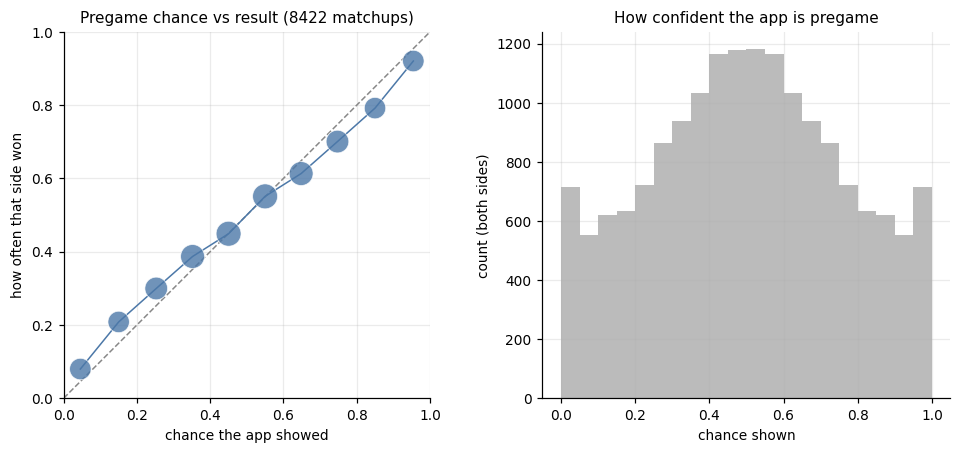

In [7]:
y, p = M.y.to_numpy(), M.pre_p.to_numpy()
z = (M.pts_a - M.pts_b - (M.mu_a - M.mu_b)) / (sqrt(2) * M.sd)
M['z'] = z
pre_row = lambda q, yy, zz: dict(matchups=len(q), brier=brier(q, yy), logloss=logloss(q, yy), slope=slope(q, yy), z_sd=float(zz.std()), z_mean=float(zz.mean()))
PRE = pd.DataFrame({'coin flip (0.5)': dict(matchups=len(p), brier=.25, logloss=np.log(2), slope=np.nan, z_sd=np.nan, z_mean=np.nan),
                    'pregame chance': pre_row(p, y, z)}).T
display(PRE.round(4))
rel = reliability(p, y); display(rel.round(3))
print('favourite (p>0.5) wins:', round(float(np.mean(np.where(p > .5, y, 1 - y))), 3), ' mean |p-0.5|+0.5 shown:', round(float(np.mean(np.maximum(p, 1 - p))), 3))

fig, ax = plt.subplots(1, 2, figsize=(9, 4.2), gridspec_kw={'width_ratios': [1, 1]})
rel_panel(ax[0], rel, f'Pregame chance vs result ({len(M)} matchups)', COL['lin']); ax[0].set_ylabel('how often that side won')
ax[1].hist(np.concatenate([p, 1 - p]), bins=20, range=(0, 1), color='#bbb'); ax[1].set_title('How confident the app is pregame'); ax[1].set_xlabel('chance shown'); ax[1].set_ylabel('count (both sides)')
fig.tight_layout(); fig.savefig(FIG / 'live_pregame_reliability.png'); plt.show()

## Analysis 2. Live calibration by stage of the week

Each replayed moment is a **state**. We group states by how much of the week is still to play, `R = (R_a + R_b) / 2` (1 = nothing
played, 0 = all done), and score the live formula in each group, once per proxy for "points so far". Two baselines for context, both
scored with Brier:

* **leader holds**: say 100% for whoever has more points right now (0% if behind, 50% if level). A formula that cannot beat this has
  added nothing to just reading the scoreboard.
* **pregame chance held fixed**: keep showing the pregame number all week.

States from one matchup are highly correlated (same players, same result), so the counts below overstate how much independent
evidence there is. The bootstrap in Analysis 6 accounts for this.

,stage,proxy,states,matchups,brier,logloss,slope,brier_leader_holds,brier_pregame_fixed
0,pregame,proxy A (linear),8422,8422,0.2001,0.5820,0.7767,0.2500,0.2000
1,pregame,proxy B (team share),8422,8422,0.2001,0.5820,0.7767,0.2500,0.2000
2,"R in (0.75,1)",proxy A (linear),44362,8390,0.1856,0.5459,0.8425,0.4275,0.2010
3,"R in (0.75,1)",proxy B (team share),44362,8390,0.1904,0.5588,0.7864,0.4269,0.2010
4,"R in (0.5,0.75]",proxy A (linear),20982,8422,0.1419,0.4346,0.9242,0.3375,0.2000
5,"R in (0.5,0.75]",proxy B (team share),20982,8422,0.1543,0.4720,0.7743,0.3488,0.2000
6,"R in (0.25,0.5]",proxy A (linear),40553,8422,0.1055,0.3333,0.8680,0.2678,0.2007
7,"R in (0.25,0.5]",proxy B (team share),40553,8422,0.1143,0.3618,0.7717,0.2764,0.2007
8,"R in (0,0.25]",proxy A (linear),77036,8422,0.0540,0.1758,0.9231,0.1480,0.1996
9,"R in (0,0.25]",proxy B (team share),77036,8422,0.0614,0.2011,0.8128,0.1544,0.1996


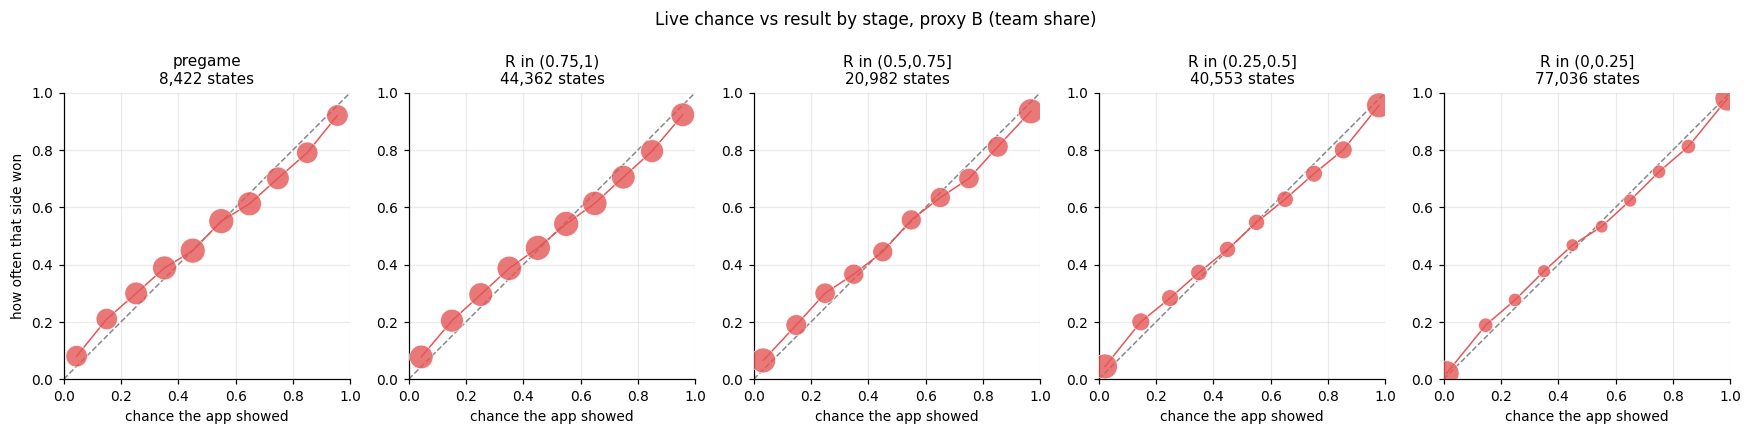

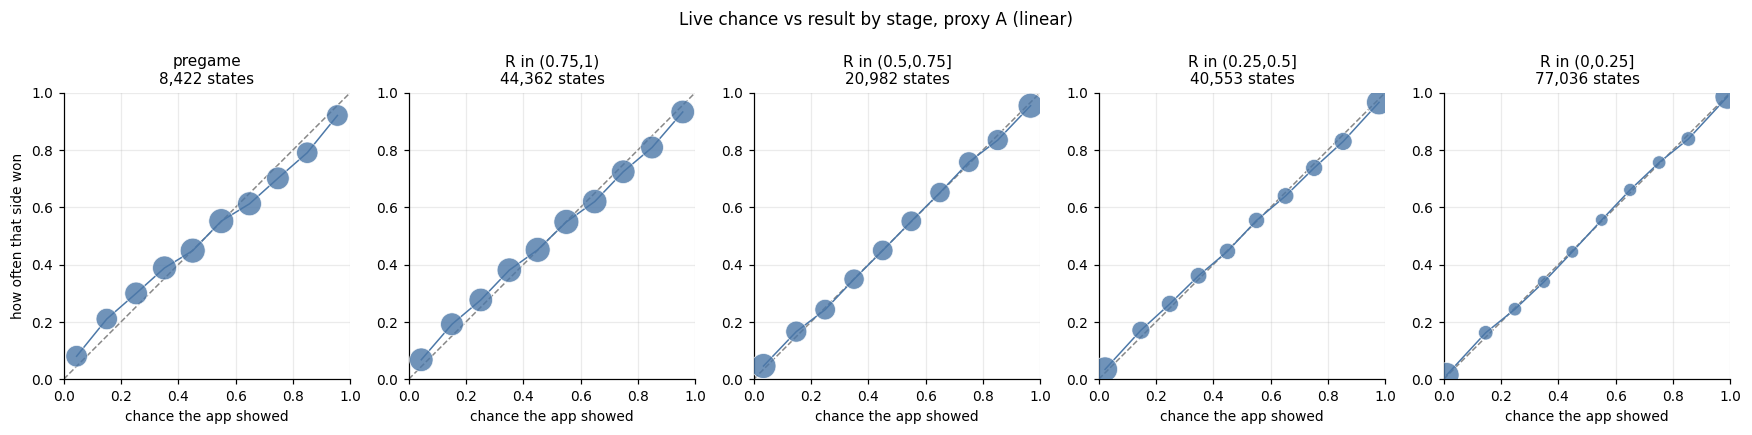

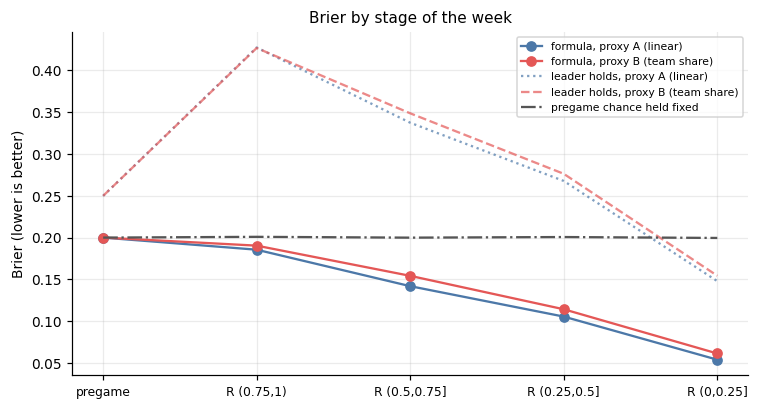

In [8]:
def p_state(df, px, k=1.0, alpha=0.5):
    """the app's live chance for the states in df under proxy px, with optional sd multiplier k and shrink exponent alpha"""
    return win_prob_v(df[f'proj_a_{px}'] - df[f'proj_b_{px}'], k * df.sd * df.Rbar ** alpha)

def lead_p(df, px): return np.where(df[f'pts_a_{px}'] > df[f'pts_b_{px}'], 1.0, np.where(df[f'pts_a_{px}'] < df[f'pts_b_{px}'], 0.0, 0.5))

def score_block(df, px):
    yy = df.y.to_numpy(); q = p_state(df, px).to_numpy()
    return dict(states=len(df), matchups=df.mi.nunique(), brier=brier(q, yy), logloss=logloss(q, yy), slope=slope(q, yy),
                brier_leader_holds=brier(lead_p(df, px), yy), brier_pregame_fixed=brier(df.pre_p.to_numpy(), yy))

rows = []
for st in STAGES:
    d = X[X.stage == st]
    for px in ('lin', 'shr'): rows.append({'stage': st, 'proxy': PNAME[px], **score_block(d, px)})
ST = pd.DataFrame(rows); display(ST.round(4))

def stage_fig(px, fn):
    fig, axs = plt.subplots(1, 5, figsize=(16, 3.7))
    for ax, st in zip(axs, STAGES):
        d = X[X.stage == st]; rp = reliability(p_state(d, px).to_numpy(), d.y.to_numpy())
        rel_panel(ax, rp, f'{st}\n{len(d):,} states', COL[px])
    axs[0].set_ylabel('how often that side won'); fig.suptitle(f'Live chance vs result by stage, {PNAME[px]}', y=1.02, fontsize=11)
    fig.tight_layout(); fig.savefig(FIG / fn, bbox_inches='tight'); plt.show()
stage_fig('shr', 'live_reliability_by_stage.png')
stage_fig('lin', 'live_reliability_by_stage_linear.png')

fig, ax = plt.subplots(figsize=(7, 3.8)); xs = np.arange(len(STAGES))
for lab, col, ls in (('formula, proxy A (linear)', COL['lin'], '-'), ('formula, proxy B (team share)', COL['shr'], '-')):
    px = 'lin' if 'linear' in lab else 'shr'
    ax.plot(xs, ST[ST.proxy == PNAME[px]].brier, marker='o', color=col, ls=ls, label=lab)
for px, ls in (('lin', ':'), ('shr', '--')):
    ax.plot(xs, ST[ST.proxy == PNAME[px]].brier_leader_holds, color=COL[px], ls=ls, alpha=.7, label=f'leader holds, {PNAME[px]}')
ax.plot(xs, ST[ST.proxy == PNAME['lin']].brier_pregame_fixed, color='#555', ls='-.', label='pregame chance held fixed')
ax.set_xticks(xs, [s.replace('R in ', 'R ') for s in STAGES], fontsize=8); ax.set_ylabel('Brier (lower is better)'); ax.set_title('Brier by stage of the week'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / 'live_brier_by_stage.png'); plt.show()

## Analysis 3. Overall, all live states

All states with something already played and something still to play (`0 < R < 1`), pooled.

In [9]:
d = X[LIVE]
OV = pd.DataFrame({PNAME[px]: score_block(d, px) for px in ('lin', 'shr')}).T; display(OV.round(4))

,states,matchups,brier,logloss,slope,brier_leader_holds,brier_pregame_fixed
proxy A (linear),182933.0,8422.0,0.1074,0.3301,0.8889,0.2641,0.2002
proxy B (team share),182933.0,8422.0,0.1151,0.3545,0.7915,0.2698,0.2002


## Analysis 4. Sensitivity: is the spread (or how it shrinks) the problem?

Two knobs, each tried on the live states (`0 < R < 1`) under both proxies:

* **(a) SD multiplier `k`**: use `k x sd` instead of `sd`. If the model's SD is too small (overconfident), `k > 1` fits better.
* **(b) Shrink exponent `alpha`**: `sd x R^alpha`. The app uses `alpha = 0.5` (variance proportional to the time left). `alpha = 1`
  means the SD itself shrinks in proportion to the time left. **Proxy A mechanically favours alpha = 1** (see the bias note above), so a
  win for alpha = 1 under proxy A says little; proxy B is the fairer judge.

We compare **log loss** (lower is better). The tables show every combination; the last one is the best `k` for each stage at `alpha = 0.5` on a finer grid.

proxy A (linear) - live log loss (app = k=1.0, alpha=0.5)


,alpha=0.5,alpha=0.75,alpha=1.0
k=0.8,0.343000,0.375600,0.423000
k=0.9,0.334500,0.360300,0.404000
k=1.0,0.330100,0.349500,0.389300
k=1.1,0.328600,0.342100,0.377700
k=1.2,0.329000,0.337200,0.368700
k=1.4,0.333600,0.332600,0.356400


  best on the grid: ('k=1.1', 'alpha=0.5') 0.3286  | brier at the app setting 0.1074 vs best-k alpha=0.5 brier 0.1072


proxy B (team share) - live log loss (app = k=1.0, alpha=0.5)


,alpha=0.5,alpha=0.75,alpha=1.0
k=0.8,0.374800,0.418300,0.473600
k=0.9,0.362200,0.398900,0.451000
k=1.0,0.354500,0.384700,0.433100
k=1.1,0.350300,0.374200,0.418900
k=1.2,0.348500,0.366700,0.407400
k=1.4,0.349600,0.357600,0.391000


  best on the grid: ('k=1.2', 'alpha=0.5') 0.3485  | brier at the app setting 0.1151 vs best-k alpha=0.5 brier 0.1142


Each alpha at its own best k (live states):


,proxy,alpha,best_k,logloss_at_best_k
0,proxy A (linear),0.50,1.10,0.3286
1,proxy A (linear),0.75,1.50,0.3321
2,proxy A (linear),1.00,2.05,0.3442
3,proxy B (team share),0.50,1.25,0.3482
4,proxy B (team share),0.75,1.70,0.3537
5,proxy B (team share),1.00,2.40,0.3674


,proxy,stage,best_k,logloss_at_best,logloss_at_k1
0,proxy A (linear),pregame,1.25,0.5766,0.5820
1,proxy A (linear),"R in (0.75,1)",1.15,0.5431,0.5459
2,proxy A (linear),"R in (0.5,0.75]",1.10,0.4338,0.4346
3,proxy A (linear),"R in (0.25,0.5]",1.15,0.3308,0.3333
4,proxy A (linear),"R in (0,0.25]",1.10,0.1750,0.1758
5,proxy B (team share),pregame,1.25,0.5766,0.5820
6,proxy B (team share),"R in (0.75,1)",1.25,0.5534,0.5588
7,proxy B (team share),"R in (0.5,0.75]",1.25,0.4641,0.4720
8,proxy B (team share),"R in (0.25,0.5]",1.25,0.3533,0.3618
9,proxy B (team share),"R in (0,0.25]",1.25,0.1959,0.2011


pregame (plain app chance, no clock): best k = 1.25  log loss at best 0.5767  at k=1 0.5818


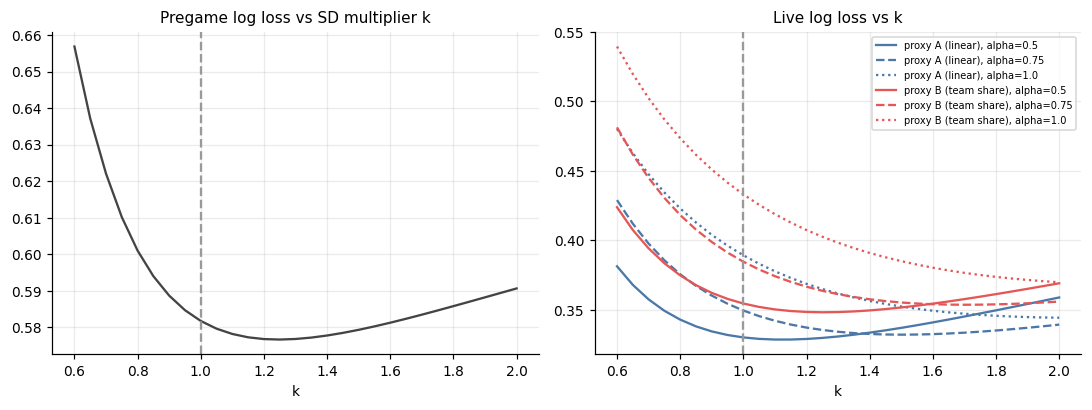

In [10]:
K_GRID, A_GRID = [0.8, 0.9, 1.0, 1.1, 1.2, 1.4], [0.5, 0.75, 1.0]
d = X[LIVE]; yl = d.y.to_numpy(); SENS = {}
for px in ('lin', 'shr'):
    SENS[px] = pd.DataFrame({f'alpha={a}': [logloss(p_state(d, px, k, a).to_numpy(), yl) for k in K_GRID] for a in A_GRID}, index=[f'k={k}' for k in K_GRID])
    print(PNAME[px], '- live log loss (app = k=1.0, alpha=0.5)'); display(SENS[px].round(4).style.highlight_min(axis=None, color='#cfe8cf'))
    print('  best on the grid:', SENS[px].stack().idxmin(), round(SENS[px].stack().min(), 4), ' | brier at the app setting', round(brier(p_state(d, px).to_numpy(), yl), 4),
          'vs best-k alpha=0.5 brier', round(min(brier(p_state(d, px, k).to_numpy(), yl) for k in K_GRID), 4))
# each alpha gets its own best k (finer and wider grid), so alpha is compared at its best k rather than at k = 1
KF2 = np.round(np.arange(0.6, 3.01, 0.05), 2); rowsa = []
for px in ('lin', 'shr'):
    for a in A_GRID:
        ll = [logloss(p_state(d, px, k, a).to_numpy(), yl) for k in KF2]
        rowsa.append({'proxy': PNAME[px], 'alpha': a, 'best_k': KF2[int(np.argmin(ll))], 'logloss_at_best_k': min(ll)})
print('Each alpha at its own best k (live states):'); display(pd.DataFrame(rowsa).round(4))
KF = np.round(np.arange(0.6, 2.01, 0.05), 2)
rowsk = []
for px in ('lin', 'shr'):
    for st in ['pregame'] + STAGES[1:]:
        dd = X[X.stage == st]; ll = [logloss(p_state(dd, px, k).to_numpy(), dd.y.to_numpy()) for k in KF]
        rowsk.append({'proxy': PNAME[px], 'stage': st, 'best_k': KF[int(np.argmin(ll))], 'logloss_at_best': min(ll), 'logloss_at_k1': ll[list(KF).index(1.0)]})
BESTK = pd.DataFrame(rowsk); display(BESTK.round(4))
llp = [logloss(win_prob_v(M.mu_a - M.mu_b, k * M.sd).to_numpy(), y) for k in KF]
print('pregame (plain app chance, no clock): best k =', KF[int(np.argmin(llp))], ' log loss at best', round(min(llp), 4), ' at k=1', round(llp[list(KF).index(1.0)], 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(KF, llp, color='#444'); ax[0].axvline(1, color='#999', ls='--'); ax[0].set_title('Pregame log loss vs SD multiplier k'); ax[0].set_xlabel('k')
for px in ('lin', 'shr'):
    for a, ls in zip(A_GRID, ('-', '--', ':')):
        ax[1].plot(KF, [logloss(p_state(d, px, k, a).to_numpy(), yl) for k in KF], color=COL[px], ls=ls, label=f'{PNAME[px]}, alpha={a}')
ax[1].axvline(1, color='#999', ls='--'); ax[1].set_title('Live log loss vs k'); ax[1].set_xlabel('k'); ax[1].legend(fontsize=6.5)
fig.tight_layout(); fig.savefig(FIG / 'live_sensitivity.png'); plt.show()

## Analysis 5. 2025 only versus all seasons

The same headline numbers split by season, plus the owner's own league. The owner's league (8 teams, 2025) is far too small to
say anything alone, so only its size is shown.

In [11]:
def head_row(Mm, Xm):
    r = dict(matchups=len(Mm), pre_brier=brier(Mm.pre_p.to_numpy(), Mm.y.to_numpy()), pre_slope=slope(Mm.pre_p.to_numpy(), Mm.y.to_numpy()), z_sd=float(Mm.z.std()), live_states=int((Xm.index.size)))
    for px in ('lin', 'shr'):
        q = p_state(Xm, px).to_numpy(); r[f'brier_{px}'] = brier(q, Xm.y.to_numpy()); r[f'slope_{px}'] = slope(q, Xm.y.to_numpy())
    return r
XL = X[LIVE]
BYS = pd.DataFrame({**{s: head_row(M[M.season == s], XL[XL.season == s]) for s in sorted(M.season.unique())}, 'all seasons': head_row(M, XL)}).T
display(BYS.round(4))
lgs = M.groupby('lg_hash').apply(lambda g_: pd.Series({'matchups': len(g_), 'brier': brier(g_.pre_p.to_numpy(), g_.y.to_numpy())}), include_groups=False).sort_values('brier')
print('pregame Brier across league-seasons: min', round(lgs.brier.iloc[0], 3), f'(league {lgs.index[0]})', '| median', round(lgs.brier.median(), 3), '| max', round(lgs.brier.iloc[-1], 3), f'(league {lgs.index[-1]})')
print('owner league: matchups', int((M.li == 0).sum()), '| states', int((X.li == 0).sum()), '| live states', int((XL.li == 0).sum()))

,matchups,pre_brier,pre_slope,z_sd,live_states,brier_lin,slope_lin,brier_shr,slope_shr
2023,3358.0,0.1953,0.8000,1.2798,71866.0,0.1040,0.8968,0.1113,0.8057
2024,2643.0,0.2061,0.7870,1.2340,56592.0,0.1109,0.8891,0.1188,0.7858
2025,2421.0,0.2001,0.7515,1.2376,54475.0,0.1082,0.8786,0.1163,0.7795
all seasons,8422.0,0.2000,0.7816,1.2536,182933.0,0.1074,0.8889,0.1151,0.7915


pregame Brier across league-seasons: min 0.134 (league bb95b6) | median 0.2 | max 0.271 (league e918c4)
owner league: matchups 52 | states 1316 | live states 1212


## Analysis 6. How sure are the numbers?

Resampling matchups would pretend the many states of one matchup are independent. Instead we resample **whole league-seasons**
(with replacement, 500 times) and recompute each headline number; the table shows the 95% range of those repeats. The pregame row
uses one point per matchup; the stage rows use all states in the stage.

In [12]:
NB = 500; rng = np.random.default_rng(2025); used = np.unique(M.li); nL = len(LEAGUES)      # resample the league-seasons actually used
WTS = [np.bincount(rng.choice(used, len(used)), minlength=nL) for _ in range(NB)]
pieces = {'pregame (plain pregame chance)': dict(q=p, y=y, lg=M.li.to_numpy(), z=M.z.to_numpy(), base_lead=None, base_pre=None)}
for px in ('lin', 'shr'):
    for st in STAGES[1:] + ['all live']:
        dd = XL if st == 'all live' else X[X.stage == st]
        pieces[f'{PNAME[px]} | {st}'] = dict(q=p_state(dd, px).to_numpy(), y=dd.y.to_numpy(), lg=dd.li.to_numpy(), z=None,
                                            base_lead=lead_p(dd, px), base_pre=dd.pre_p.to_numpy())
t0 = time.time(); BOOT = {k: defaultdict(list) for k in pieces}
for wl in WTS:
    for k, pc in pieces.items():
        w = wl[pc['lg']].astype(float); sw = w.sum(); yy = pc['y']
        sq = (pc['q'] - yy) ** 2; BOOT[k]['brier'].append(np.sum(w * sq) / sw)
        BOOT[k]['logloss'].append(logloss(pc['q'], yy, w))
        BOOT[k]['slope'].append(slope(pc['q'], yy, w, pc.setdefault('b0', slope(pc['q'], yy))))
        if pc['base_lead'] is not None:
            BOOT[k]['brier_leader_holds'].append(np.sum(w * (pc['base_lead'] - yy) ** 2) / sw)
            BOOT[k]['brier_pregame_fixed'].append(np.sum(w * (pc['base_pre'] - yy) ** 2) / sw)
        if pc['z'] is not None:
            m = np.sum(w * pc['z']) / sw; BOOT[k]['z_sd'].append(np.sqrt(np.sum(w * (pc['z'] - m) ** 2) / sw)); BOOT[k]['z_mean'].append(m)
print(f'bootstrap of {NB} league-season resamples took {time.time() - t0:.0f}s')

def fmt(v, point):
    lo, hi = np.percentile(v, [2.5, 97.5]); return f'{point:.3f} [{lo:.3f}, {hi:.3f}]'
point = {'brier': brier, 'logloss': logloss, 'slope': slope}
rows = {}
for k, pc in pieces.items():
    r = {m_: fmt(BOOT[k][m_], point[m_](pc['q'], pc['y'])) for m_ in ('brier', 'logloss', 'slope')}
    if pc['base_lead'] is not None:
        r['brier_leader_holds'] = fmt(BOOT[k]['brier_leader_holds'], brier(pc['base_lead'], pc['y'])); r['brier_pregame_fixed'] = fmt(BOOT[k]['brier_pregame_fixed'], brier(pc['base_pre'], pc['y']))
    if pc['z'] is not None:
        r['z_sd'] = fmt(BOOT[k]['z_sd'], float(pc['z'].std())); r['z_mean'] = fmt(BOOT[k]['z_mean'], float(pc['z'].mean()))
    rows[k] = r
CI = pd.DataFrame(rows).T.fillna(''); pd.set_option('display.width', 250, 'display.max_colwidth', 40); display(CI)

bootstrap of 500 league-season resamples took 81s


,brier,logloss,slope,z_sd,z_mean,brier_leader_holds,brier_pregame_fixed
pregame (plain pregame chance),"0.200 [0.194, 0.206]","0.582 [0.567, 0.595]","0.782 [0.744, 0.822]","1.254 [1.235, 1.275]","0.020 [-0.007, 0.047]",,
"proxy A (linear) | R in (0.75,1)","0.186 [0.180, 0.191]","0.546 [0.531, 0.560]","0.843 [0.800, 0.889]",,,"0.428 [0.416, 0.439]","0.201 [0.195, 0.207]"
"proxy A (linear) | R in (0.5,0.75]","0.142 [0.137, 0.147]","0.435 [0.420, 0.450]","0.924 [0.876, 0.975]",,,"0.338 [0.326, 0.347]","0.200 [0.193, 0.206]"
"proxy A (linear) | R in (0.25,0.5]","0.106 [0.101, 0.110]","0.333 [0.319, 0.347]","0.868 [0.824, 0.915]",,,"0.268 [0.257, 0.278]","0.201 [0.195, 0.207]"
"proxy A (linear) | R in (0,0.25]","0.054 [0.051, 0.057]","0.176 [0.166, 0.185]","0.923 [0.883, 0.967]",,,"0.148 [0.142, 0.155]","0.200 [0.193, 0.205]"
proxy A (linear) | all live,"0.107 [0.104, 0.111]","0.330 [0.320, 0.340]","0.889 [0.857, 0.924]",,,"0.264 [0.258, 0.270]","0.200 [0.194, 0.206]"
"proxy B (team share) | R in (0.75,1)","0.190 [0.184, 0.196]","0.559 [0.543, 0.574]","0.786 [0.747, 0.829]",,,"0.427 [0.417, 0.438]","0.201 [0.195, 0.207]"
"proxy B (team share) | R in (0.5,0.75]","0.154 [0.149, 0.160]","0.472 [0.455, 0.487]","0.774 [0.738, 0.813]",,,"0.349 [0.337, 0.358]","0.200 [0.193, 0.206]"
"proxy B (team share) | R in (0.25,0.5]","0.114 [0.109, 0.119]","0.362 [0.346, 0.376]","0.772 [0.735, 0.813]",,,"0.276 [0.265, 0.286]","0.201 [0.195, 0.207]"
"proxy B (team share) | R in (0,0.25]","0.061 [0.058, 0.064]","0.201 [0.191, 0.211]","0.813 [0.786, 0.842]",,,"0.154 [0.148, 0.162]","0.200 [0.193, 0.205]"


## What this says

* **Pregame the app is overconfident.** Over 8,422 matchups (104 league-seasons) the pregame chance scores Brier 0.200 (95% range 0.194-0.206; always saying 50% is 0.250) and log loss 0.582, but the
  calibration slope is **0.78 (0.74-0.82)**: when the app shows 90-100% the side wins 92% of the time (it shows 95%), and its 0-10% calls win 8%. On average it shows the favourite at 71.6% and the
  favourite wins 68.5%. The cause is the spread: the real score difference is wider than the model's, z-SD **1.25 (1.23-1.28)** instead of 1. Scaling `sd` by about 1.25 is the best fit (log loss 0.582 to 0.577).
  This is also the matchup model inside the season simulation, so simulated seasons will be somewhat too deterministic.
* **The live chance inherits the same overconfidence at every stage; the clock does not add a new problem.** Proxy B (team-scoring share, the more realistic one): slope 0.79 (R in (0.75,1)), 0.77,
  0.77, 0.81 (R in (0,0.25]), overall 0.79 (0.77-0.82), Brier 0.190 / 0.154 / 0.114 / 0.061, overall 0.115. Proxy A (linear), which was expected to look *under*confident, still reads slightly over: slopes 0.84, 0.92, 0.87, 0.92,
  overall 0.89 (0.86-0.92), Brier 0.186 / 0.142 / 0.106 / 0.054, overall 0.107. Many of the stage slopes have 95% ranges that exclude 1, but only modestly (a slope of 0.8 means a stated 80% is really about 77%).
* **It is clearly useful.** Overall Brier is 0.107 (A) and 0.115 (B) versus 0.264 / 0.270 for "the leader holds" and 0.200 for holding the pregame number fixed, and it beats the pregame number at every stage.
  Early in the week (R above 0.75) the edge over the fixed pregame number is small (0.186 / 0.190 vs 0.201).
* **Sensitivity.** A multiplier `k` on `sd` of about 1.1 (proxy A) to 1.2-1.25 (proxy B) fits best, the same direction and size as the pregame result, but the gain is small (live Brier 0.1074 to 0.1072 under A,
  0.1151 to 0.1142 under B; log loss 0.330 to 0.329 and 0.355 to 0.348). The app's square-root shrink (`alpha = 0.5`) fits best under both proxies even when every `alpha` gets its own best `k`
  (log loss 0.329 at alpha 0.5 vs 0.332 at 0.75 and 0.344 at 1 under A; 0.348 / 0.354 / 0.367 under B); alpha = 1 needs `k` of 2 or more to compete. I expected proxy A to favour alpha = 1; it does not.
* **Stable across seasons.** 2025 alone gives the same picture (pregame slope 0.75, z-SD 1.24, live slope 0.88 under A and 0.78 under B). The owner's own league has only 52 matchups (1,316 states), too few to say anything alone.
* **Caveats.** Both proxies derive "points so far" from final points, so absolute Brier values are optimistic and the live slopes are only indicative; the lingering overconfidence is real
  but its size is uncertain. True intra-game timing needs play-by-play (nflverse could supply it, a follow-up). Data dropped: 1 league-season with no recorded playoff week, 2 with no matchup data,
  18 matchups where a starter scored with no known NFL game, 2 exact ties.